# Parte Específica: Outliers do BankChurners

**Pergunta:** os valores extremos das variáveis numéricas são erros ou clientes reais? E o que fazer com eles?

**Critérios** (os mesmos da Parte Comum): **IQR** (abaixo de Q1 − 1,5·IQR ou acima de Q3 + 1,5·IQR) e
**z-score** (|z| > 3). Os dados são o `bankchurners_tratado.csv` (gerado por `eda_unknown.ipynb`).

A lógica fica em `outliers.py` (com testes em `tests/parte_especifica/`); este notebook só chama as
funções e mostra os resultados. A página **Outliers** do dashboard usa as mesmas funções.

> Execute este notebook a partir da pasta `src/parte_especifica/` (ele importa `outliers.py` e lê
> os arquivos por caminho relativo `../../out/...`).

In [1]:
# [IA] Claude Code – importação das bibliotecas, funções de outliers e leitura do dataset tratado
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from outliers import K_IQR, mascara_outliers, resumo_outliers, taxa_alvo_por_grupo, tratar

CAMINHO_DADOS = Path("../../out/parte_especifica/bankchurners_tratado.csv")
PASTA_SAIDA = Path("../../out/parte_especifica")
PASTA_SAIDA.mkdir(parents=True, exist_ok=True)

# Mesmas cores do grupo: azul = ficou, vermelho = cancelou
COR_CANCELOU = "#C44E52"
ALVO, CANCELOU = "Attrition_Flag", "Attrited Customer"

df = pd.read_csv(CAMINHO_DADOS)
colunas_numericas = df.select_dtypes("number").columns.drop("CLIENTNUM").tolist()
print(f"{len(df)} clientes, {len(colunas_numericas)} variáveis numéricas")

10127 clientes, 14 variáveis numéricas


## 1. Quantos outliers há em cada variável?

In [2]:
# [IA] Claude Code – contagem de outliers por variável pelos critérios IQR e z-score
resumo = resumo_outliers(df, colunas_numericas)
resumo.round(2).sort_values("total", ascending=False)

,limite_inferior,limite_superior,abaixo,acima,total,pct,total_z,assimetria
variavel,,,,,,,,
Credit_Limit,-10213.75,23836.25,0,984,984,9.72,0,1.67
Avg_Open_To_Buy,-11477.25,22660.75,0,963,963,9.51,0,1.66
Total_Trans_Amt,-1722.75,8619.25,0,896,896,8.85,391,2.04
Contacts_Count_12_mon,0.50,4.50,399,230,629,6.21,54,0.01
Total_Amt_Chng_Q4_Q1,0.29,1.20,48,348,396,3.91,163,1.73
Total_Ct_Chng_Q4_Q1,0.23,1.17,96,298,394,3.89,113,2.06
Months_on_book,17.50,53.50,188,198,386,3.81,0,-0.11
Months_Inactive_12_mon,0.50,4.50,29,302,331,3.27,124,0.63
Customer_Age,24.50,68.50,0,2,2,0.02,1,-0.03


O critério IQR marca outliers em **10 das 14** variáveis, de 0,02% (`Customer_Age`, `Total_Trans_Ct`) a
9,7% (`Credit_Limit`). Já o z-score é bem mais rigoroso: `Credit_Limit` tem 984 outliers pelo IQR e
**nenhum** pelo z-score, porque a distribuição é assimétrica e o desvio padrão já é grande.
No total, **3.326 clientes (32,8%)** têm ao menos um outlier pelo IQR.

## 2. Como eles aparecem nos boxplots?

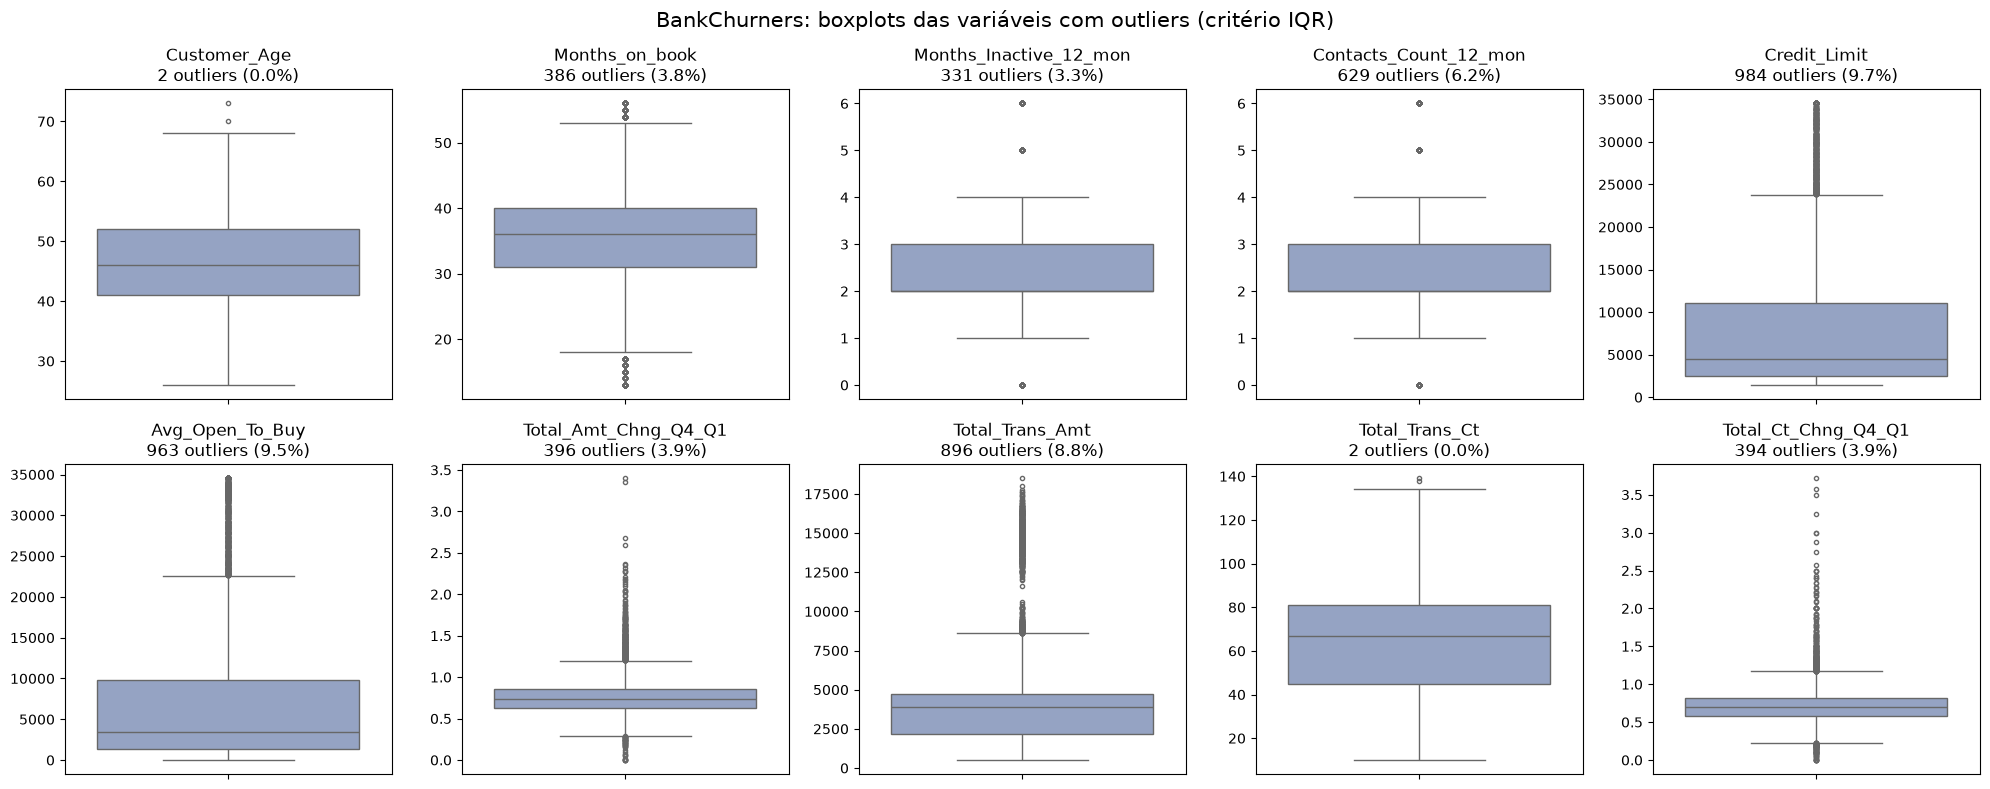

In [3]:
# [IA] Claude Code – boxplots das variáveis que têm outliers, cada uma na sua escala
com_outliers = resumo.index[resumo["total"] > 0].tolist()

n_linhas = -(-len(com_outliers) // 5)  # arredonda para cima: nenhuma variável fica de fora
fig, axes = plt.subplots(n_linhas, 5, figsize=(20, 4 * n_linhas), squeeze=False)
for ax, coluna in zip(axes.flat, com_outliers):
    sns.boxplot(y=df[coluna], ax=ax, color="#8DA0CB", flierprops={"marker": "o", "markersize": 3})
    ax.set_title(f"{coluna}\n{int(resumo.loc[coluna, 'total'])} outliers ({resumo.loc[coluna, 'pct']:.1f}%)")
    ax.set_xlabel("")
    ax.set_ylabel("")
for ax in axes.flat[len(com_outliers):]:
    ax.set_visible(False)
fig.suptitle("BankChurners: boxplots das variáveis com outliers (critério IQR)", fontsize=15)
fig.tight_layout()
fig.savefig(PASTA_SAIDA / "eda_outliers_boxplots.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. São valores plausíveis ou erros?

In [4]:
# [IA] Claude Code – faixa de valores das variáveis e dos seus outliers, para avaliar se são plausíveis
faixas = pd.DataFrame(
    {
        "mínimo": df[com_outliers].min(),
        "máximo": df[com_outliers].max(),
        "menor outlier": {c: df.loc[mascara_outliers(df[c]), c].min() for c in com_outliers},
        "maior outlier": {c: df.loc[mascara_outliers(df[c]), c].max() for c in com_outliers},
    }
)
faixas.round(2)

,mínimo,máximo,menor outlier,maior outlier
Customer_Age,26.0,73.00,70.0,73.00
Months_on_book,13.0,56.00,13.0,56.00
Months_Inactive_12_mon,0.0,6.00,0.0,6.00
Contacts_Count_12_mon,0.0,6.00,0.0,6.00
Credit_Limit,1438.3,34516.00,23848.0,34516.00
Avg_Open_To_Buy,3.0,34516.00,22664.0,34516.00
Total_Amt_Chng_Q4_Q1,0.0,3.40,0.0,3.40
Total_Trans_Amt,510.0,18484.00,8620.0,18484.00
Total_Trans_Ct,10.0,139.00,138.0,139.00
Total_Ct_Chng_Q4_Q1,0.0,3.71,0.0,3.71


Todos os extremos são **plausíveis**: limite de crédito de até US$ 34.516 (clientes de renda alta),
até US$ 18.484 transacionados em 12 meses, clientes de até 73 anos, até 56 meses de relacionamento e
até 139 transações. Nenhum valor é negativo, impossível ou fora da escala de contagem
(`Contacts_Count_12_mon` vai de 0 a 6, `Months_Inactive_12_mon` de 0 a 6).
Além disso, `Credit_Limit` e `Avg_Open_To_Buy` têm correlação de 0,996: os dois "gritam" pelos mesmos
clientes, que são os de limite alto, e não são dois problemas separados.

## 4. Ser outlier tem a ver com cancelar o cartão?

Compara a taxa de cancelamento entre os clientes que são outliers numa variável e os demais.
Se a taxa fosse igual, o outlier não carregaria informação sobre o cancelamento.

In [5]:
# [IA] Claude Code – taxa de cancelamento entre os outliers e entre os demais, por variável
cancelamento = taxa_alvo_por_grupo(df, com_outliers, alvo=ALVO, positivo=CANCELOU)
taxa_base = (df[ALVO] == CANCELOU).mean() * 100
print(f"Taxa de cancelamento da base toda: {taxa_base:.1f}%")
cancelamento.round(1).sort_values("n_outliers", ascending=False)

Taxa de cancelamento da base toda: 16.1%


,n_outliers,taxa_outliers,taxa_demais,diferenca_pp
variavel,,,,
Credit_Limit,984,16.1,16.1,-0.0
Avg_Open_To_Buy,963,16.8,16.0,0.8
Total_Trans_Amt,896,9.8,16.7,-6.9
Contacts_Count_12_mon,629,19.1,15.9,3.2
Total_Amt_Chng_Q4_Q1,396,12.6,16.2,-3.6
Total_Ct_Chng_Q4_Q1,394,22.1,15.8,6.3
Months_on_book,386,13.2,16.2,-3.0
Months_Inactive_12_mon,331,19.9,15.9,4.0
Customer_Age,2,0.0,16.1,-16.1


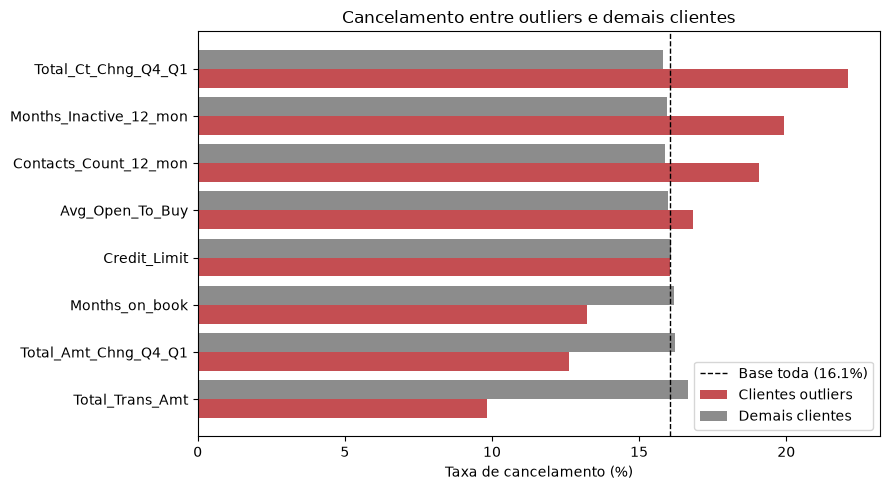

In [6]:
# [IA] Claude Code – gráfico da taxa de cancelamento dos outliers x demais clientes (variáveis com 300 ou mais outliers)
grandes = cancelamento[cancelamento["n_outliers"] >= 300].sort_values("diferenca_pp")
posicoes = list(range(len(grandes)))

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh([p - 0.2 for p in posicoes], grandes["taxa_outliers"], height=0.4, color=COR_CANCELOU, label="Clientes outliers")
ax.barh([p + 0.2 for p in posicoes], grandes["taxa_demais"], height=0.4, color="#8C8C8C", label="Demais clientes")
ax.axvline(taxa_base, color="black", linestyle="--", linewidth=1, label=f"Base toda ({taxa_base:.1f}%)")
ax.set_yticks(posicoes)
ax.set_yticklabels(grandes.index)
ax.set_xlabel("Taxa de cancelamento (%)")
ax.set_title("Cancelamento entre outliers e demais clientes")
ax.legend()
fig.tight_layout()
fig.savefig(PASTA_SAIDA / "eda_outliers_cancelamento.png", dpi=150, bbox_inches="tight")
plt.show()

Os outliers **carregam informação** sobre o cancelamento, em sentidos diferentes:
quem é outlier em `Total_Ct_Chng_Q4_Q1` cancela mais (22,1% contra 15,8%), e quem é outlier em
`Total_Trans_Amt` (grandes gastadores) cancela bem menos (9,8% contra 16,7%).
Remover esses clientes tiraria justamente os perfis mais distintos do problema.

## 5. O que acontece com cada forma de tratar?

In [7]:
# [IA] Claude Code – comparação das três estratégias (manter, limitar nas cercas do IQR, remover) nas variáveis de valor
colunas_valor = ["Credit_Limit", "Total_Trans_Amt"]

linhas = []
for rotulo, colunas in [
    ("manter", colunas_valor),
    ("limitar", colunas_valor),
    ("remover (as 2 variáveis)", colunas_valor),
    ("remover (todas as 14)", colunas_numericas),
]:
    estrategia = rotulo.split(" ")[0]
    t = tratar(df, colunas, estrategia)
    linhas.append(
        {
            "estratégia": rotulo,
            "clientes": len(t),
            "% da base mantida": len(t) / len(df) * 100,
            "cancelamento (%)": (t[ALVO] == CANCELOU).mean() * 100,
            "assimetria Credit_Limit": t["Credit_Limit"].skew(),
            "assimetria Total_Trans_Amt": t["Total_Trans_Amt"].skew(),
        }
    )
pd.DataFrame(linhas).set_index("estratégia").round(2)

,clientes,% da base mantida,cancelamento (%),assimetria Credit_Limit,assimetria Total_Trans_Amt
estratégia,,,,,
manter,10127,100.00,16.07,1.67,2.04
limitar,10127,100.00,16.07,1.20,0.84
remover (as 2 variáveis),8443,83.37,16.59,1.54,0.63
remover (todas as 14),6801,67.16,16.50,1.55,0.54


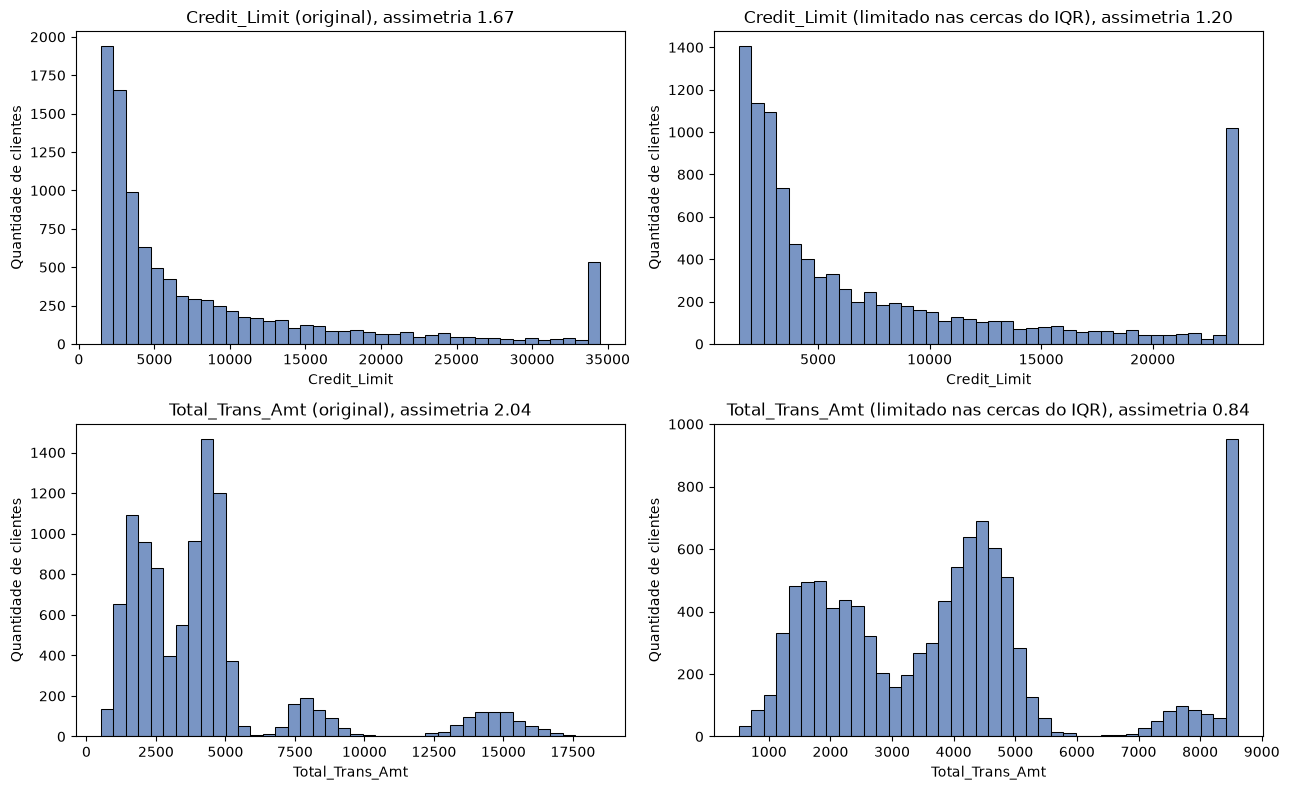

In [8]:
# [IA] Claude Code – histogramas de Credit_Limit e Total_Trans_Amt antes e depois de limitar nas cercas do IQR
limitado = tratar(df, colunas_valor, "limitar")

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for linha, coluna in enumerate(colunas_valor):
    for coluna_ax, (rotulo, dados) in enumerate([("original", df), ("limitado nas cercas do IQR", limitado)]):
        ax = axes[linha, coluna_ax]
        sns.histplot(dados[coluna], bins=40, ax=ax, color="#4C72B0")
        ax.set_title(f"{coluna} ({rotulo}), assimetria {dados[coluna].skew():.2f}")
        ax.set_xlabel(coluna)
        ax.set_ylabel("Quantidade de clientes")
fig.tight_layout()
fig.savefig(PASTA_SAIDA / "eda_outliers_tratamento.png", dpi=150, bbox_inches="tight")
plt.show()

## Decisão (proposta para revisão do grupo)

1. **Manter todos os valores no dataset do grupo.** Os extremos são plausíveis (clientes reais de renda
   alta, grandes gastadores, clientes mais velhos ou mais antigos) e não há erro de digitação nem valor
   fora da escala. Os outliers também carregam informação sobre o cancelamento (seção 4).
2. **Não remover linhas.** Tirar os outliers de todas as variáveis descartaria 3.326 clientes (32,8% da
   base) e justamente os perfis mais distintos. Remover só os de `Total_Trans_Amt` retiraria os clientes
   que mais ficam.
3. **Limitar nas cercas do IQR só como recurso de análise**, em gráficos e comparações sensíveis à escala.
   Em `Credit_Limit` e `Total_Trans_Amt` isso reduz a assimetria (de 1,67 para 1,20 e de 2,04 para 0,84)
   sem perder nenhum cliente. A página **Outliers** do dashboard deixa escolher a estratégia e ver o efeito.
4. **Variáveis de contagem** (`Contacts_Count_12_mon`, `Months_Inactive_12_mon`, `Months_on_book`,
   `Customer_Age`, `Total_Trans_Ct`): tratar como valores válidos da escala, sem ajuste.